In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = sns.load_dataset('titanic')

In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


In [6]:
num_cols = df.select_dtypes(include = ['int64','float64'])

In [7]:
num_cols.columns

Index(['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare'], dtype='str')

In [8]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [9]:
df.isnull().mean()*(100)

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64

In [10]:
df['age'].skew()

np.float64(0.38910778230082704)

In [11]:
df['age'] = df['age'].fillna(df['age'].mean())

In [12]:
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

In [13]:
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

In [14]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [15]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      0
alive            0
alone            0
dtype: int64

In [16]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [17]:
df.drop('deck',axis=1,inplace=True)

In [18]:
df.isnull().sum()


survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

In [19]:
num_cols.corr()

,survived,pclass,age,sibsp,parch,fare
survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
sibsp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


In [20]:
num_cols.skew()

survived    0.478523
pclass     -0.630548
age         0.389108
sibsp       3.695352
parch       2.749117
fare        4.787317
dtype: float64

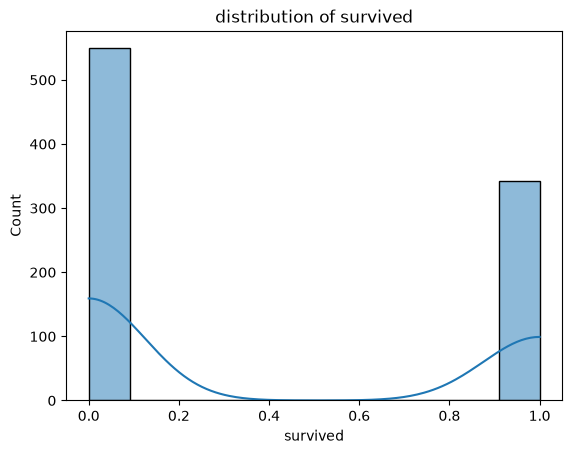

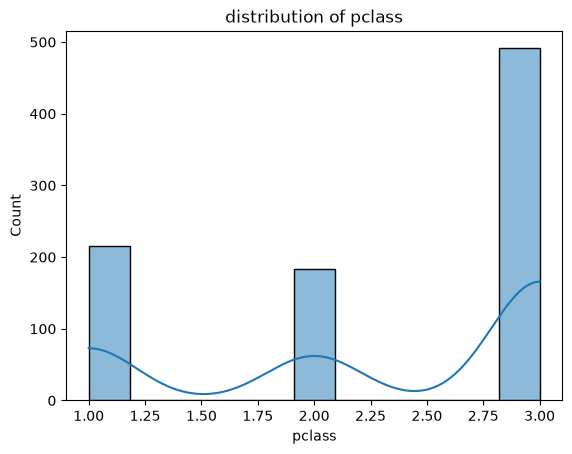

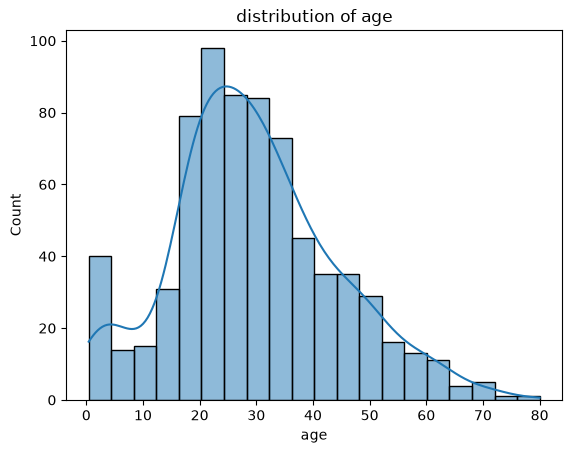

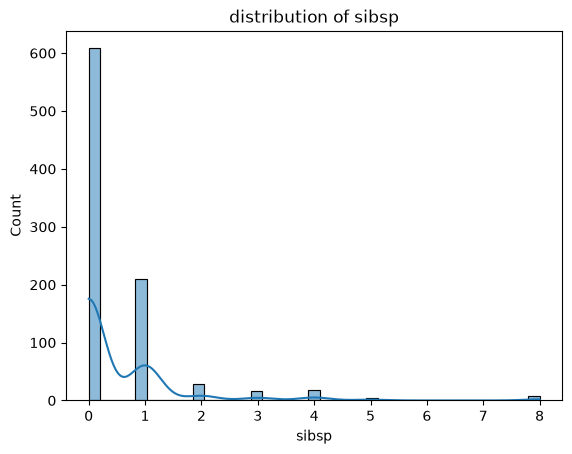

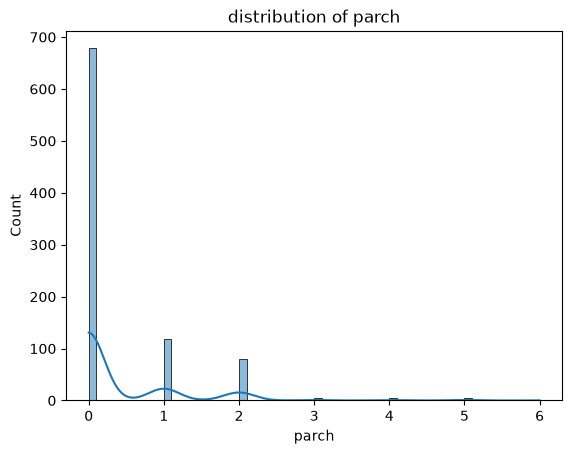

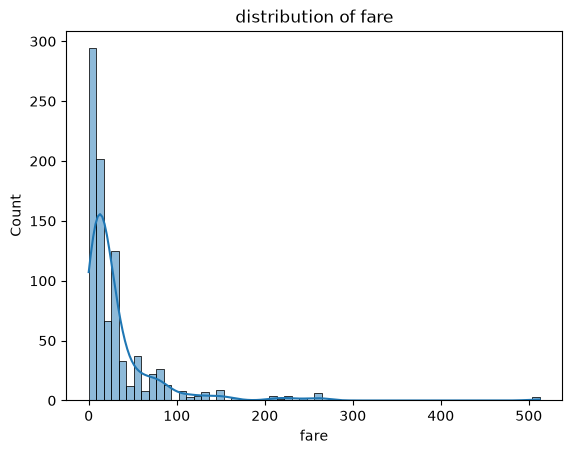

In [21]:
for col in num_cols:
    sns.histplot(num_cols[col],kde=True)
    plt.title(f'distribution of {col}')
    plt.show()
    
    

In [22]:
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3-q1
    lb = q1 - 1.5*(iqr)
    ub = q3 + 1.5*(iqr)
    outliers = (df[col] > ub) | (df[col]<lb)

In [23]:
print("Lower bound:", lb)
print("Upper bound:", ub)
print("Number of outliers:", len(outliers))

Lower bound: -26.724
Upper bound: 65.6344
Number of outliers: 891


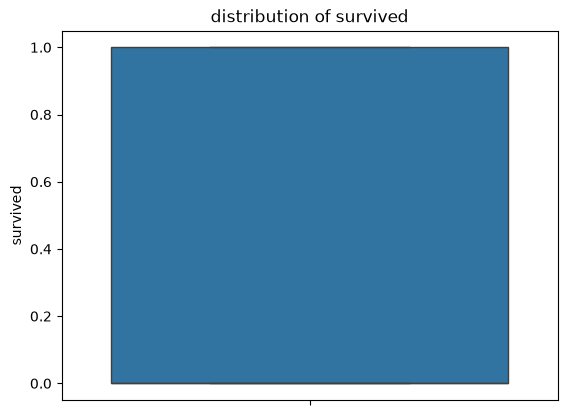

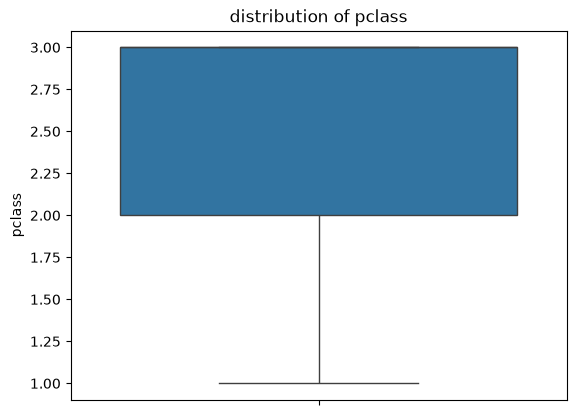

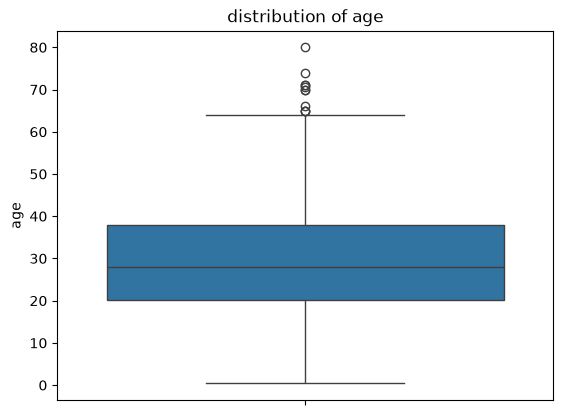

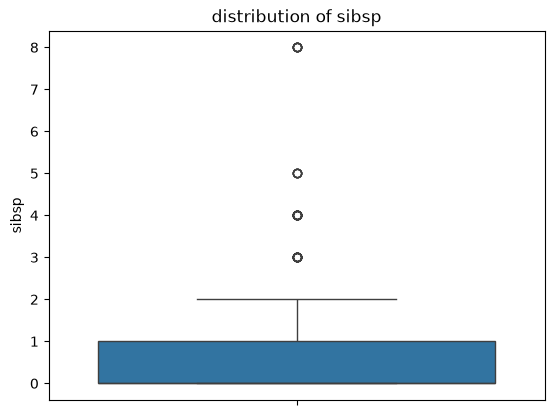

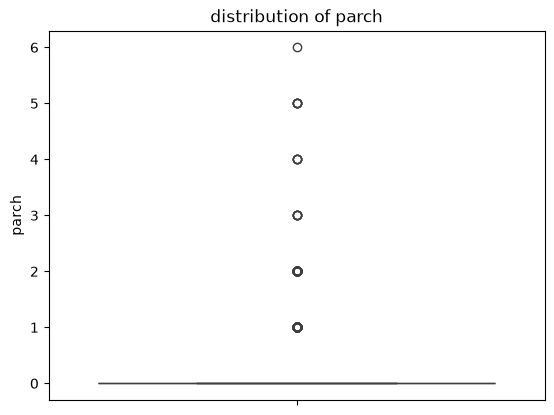

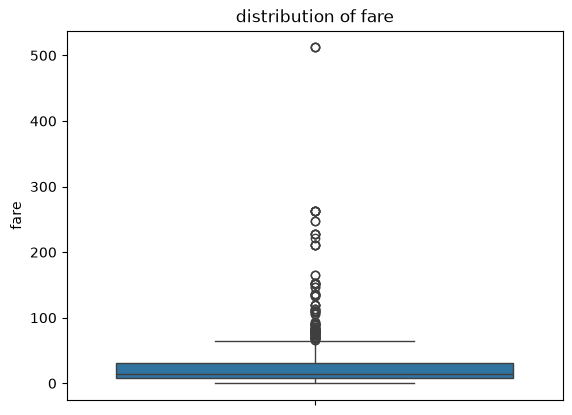

In [24]:
for col in num_cols:
    sns.boxplot(num_cols[col])
    plt.title(f'distribution of {col}')
    plt.show()
    

In [25]:
num_cols['fare_log1'] = np.log1p(num_cols['fare'])

In [26]:
num_cols['parch_log1'] = np.log1p(num_cols[
'parch'])

In [27]:
num_cols['sibsp_log1'] = np.log1p(num_cols['sibsp'])

In [28]:
num_cols.skew()

survived      0.478523
pclass       -0.630548
age           0.389108
sibsp         3.695352
parch         2.749117
fare          4.787317
fare_log1     0.394928
parch_log1    1.675439
sibsp_log1    1.661245
dtype: float64

In [29]:
from sklearn.preprocessing import PowerTransformer
import pandas as pd

# Initialize the Yeo-Johnson transformer
pt = PowerTransformer(method='yeo-johnson')

# Select the original skewed columns (not the log1p versions)
skewed_cols = ['fare', 'sibsp', 'parch']

# Fit and transform the data, then assign it to new columns
transformed_data = pt.fit_transform(num_cols[skewed_cols])
num_cols[['fare_yj', 'sibsp_yj', 'parch_yj']] = transformed_data

# Check the new skewness
print(num_cols[['fare_yj', 'sibsp_yj', 'parch_yj']].skew())

fare_yj    -0.040329
sibsp_yj    0.808608
parch_yj    1.228795
dtype: float64


In [30]:
num_cols

,survived,pclass,age,sibsp,parch,fare,fare_log1,parch_log1,sibsp_log1,fare_yj,sibsp_yj,parch_yj
0,0,3,22.0,1,0,7.2500,2.110213,0.000000,0.693147,-0.878820,1.373636,-0.560253
1,1,1,38.0,1,0,71.2833,4.280593,0.000000,0.693147,1.336651,1.373636,-0.560253
2,1,3,26.0,0,0,7.9250,2.188856,0.000000,0.000000,-0.790065,-0.679850,-0.560253
3,1,1,35.0,1,0,53.1000,3.990834,0.000000,0.693147,1.067352,1.373636,-0.560253
4,0,3,35.0,0,0,8.0500,2.202765,0.000000,0.000000,-0.774439,-0.679850,-0.560253
...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000,2.639057,0.000000,0.000000,-0.294907,-0.679850,-0.560253
887,1,1,19.0,0,0,30.0000,3.433987,0.000000,0.000000,0.527906,-0.679850,-0.560253
888,0,3,NaN,1,2,23.4500,3.196630,1.098612,0.693147,0.288885,1.373636,1.846856
889,1,1,26.0,0,0,30.0000,3.433987,0.000000,0.000000,0.527906,-0.679850,-0.560253


In [31]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [32]:
# 1. Bring the new transformed columns from num_cols into your original df
df[['fare_yj', 'sibsp_yj', 'parch_yj']] = num_cols[['fare_yj', 'sibsp_yj', 'parch_yj']]

# 2. Drop the original skewed columns (and fare_parch if you still want it gone) from df
df.drop(columns=['fare', 'sibsp', 'parch', 'fare_parch'], inplace=True, errors='ignore')

In [33]:
df.head()

,survived,pclass,sex,age,embarked,class,who,adult_male,embark_town,alive,alone,fare_yj,sibsp_yj,parch_yj
0,0,3,male,22.0,S,Third,man,True,Southampton,no,False,-0.878820,1.373636,-0.560253
1,1,1,female,38.0,C,First,woman,False,Cherbourg,yes,False,1.336651,1.373636,-0.560253
2,1,3,female,26.0,S,Third,woman,False,Southampton,yes,True,-0.790065,-0.679850,-0.560253
3,1,1,female,35.0,S,First,woman,False,Southampton,yes,False,1.067352,1.373636,-0.560253
4,0,3,male,35.0,S,Third,man,True,Southampton,no,True,-0.774439,-0.679850,-0.560253


In [34]:
num_cols.drop(columns = ['sibsp','fare','fare_log1','parch','parch_log1','sibsp_log1'],inplace = True)

In [35]:
outlier_summary = []

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = (df[col] < lower) | (df[col] > upper)

    outlier_summary.append({
        "column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": mask.sum(),
        "outlier_percentage": mask.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,survived,0.000000,1.000000,1.000000,-1.500000,2.500000,0,0.000000
1,pclass,2.000000,3.000000,1.000000,0.500000,4.500000,0,0.000000
2,age,22.000000,35.000000,13.000000,2.500000,54.500000,66,7.407407
3,fare_yj,-0.791907,0.559458,1.351366,-2.818956,2.586507,18,2.020202
4,sibsp_yj,-0.679850,1.373636,2.053486,-3.760080,4.453866,0,0.000000
5,parch_yj,-0.560253,-0.560253,0.000000,-0.560253,-0.560253,213,23.905724


In [36]:
df.head()

,survived,pclass,sex,age,embarked,class,who,adult_male,embark_town,alive,alone,fare_yj,sibsp_yj,parch_yj
0,0,3,male,22.0,S,Third,man,True,Southampton,no,False,-0.878820,1.373636,-0.560253
1,1,1,female,38.0,C,First,woman,False,Cherbourg,yes,False,1.336651,1.373636,-0.560253
2,1,3,female,26.0,S,Third,woman,False,Southampton,yes,True,-0.790065,-0.679850,-0.560253
3,1,1,female,35.0,S,First,woman,False,Southampton,yes,False,1.067352,1.373636,-0.560253
4,0,3,male,35.0,S,Third,man,True,Southampton,no,True,-0.774439,-0.679850,-0.560253


In [37]:
categorical_columns = ['sex', 'embarked', 'class', 'who']

In [38]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

encoded = encoder.fit_transform(df[categorical_columns])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(categorical_columns),
    index=df.index
)

encoded_df.head()

,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,class_First,class_Second,class_Third,who_child,who_man,who_woman
0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0


In [39]:
df.head()

,survived,pclass,sex,age,embarked,class,who,adult_male,embark_town,alive,alone,fare_yj,sibsp_yj,parch_yj
0,0,3,male,22.0,S,Third,man,True,Southampton,no,False,-0.878820,1.373636,-0.560253
1,1,1,female,38.0,C,First,woman,False,Cherbourg,yes,False,1.336651,1.373636,-0.560253
2,1,3,female,26.0,S,Third,woman,False,Southampton,yes,True,-0.790065,-0.679850,-0.560253
3,1,1,female,35.0,S,First,woman,False,Southampton,yes,False,1.067352,1.373636,-0.560253
4,0,3,male,35.0,S,Third,man,True,Southampton,no,True,-0.774439,-0.679850,-0.560253


In [40]:
# Remove original categorical columns
df = df.drop(columns=categorical_columns)

# Add one-hot encoded columns
df = pd.concat([df, encoded_df], axis=1)

# Check the result
df.head()

,survived,pclass,age,adult_male,embark_town,alive,alone,fare_yj,sibsp_yj,parch_yj,...,sex_male,embarked_C,embarked_Q,embarked_S,class_First,class_Second,class_Third,who_child,who_man,who_woman
0,0,3,22.0,True,Southampton,no,False,-0.878820,1.373636,-0.560253,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,1,1,38.0,False,Cherbourg,yes,False,1.336651,1.373636,-0.560253,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,1,3,26.0,False,Southampton,yes,True,-0.790065,-0.679850,-0.560253,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
3,1,1,35.0,False,Southampton,yes,False,1.067352,1.373636,-0.560253,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0,3,35.0,True,Southampton,no,True,-0.774439,-0.679850,-0.560253,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0


In [41]:
df = df.drop(columns=['adult_male'])


In [42]:
df

,survived,pclass,age,embark_town,alive,alone,fare_yj,sibsp_yj,parch_yj,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,class_First,class_Second,class_Third,who_child,who_man,who_woman
0,0,3,22.000000,Southampton,no,False,-0.878820,1.373636,-0.560253,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,1,1,38.000000,Cherbourg,yes,False,1.336651,1.373636,-0.560253,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,1,3,26.000000,Southampton,yes,True,-0.790065,-0.679850,-0.560253,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
3,1,1,35.000000,Southampton,yes,False,1.067352,1.373636,-0.560253,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0,3,35.000000,Southampton,no,True,-0.774439,-0.679850,-0.560253,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,27.000000,Southampton,no,True,-0.294907,-0.679850,-0.560253,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
887,1,1,19.000000,Southampton,yes,True,0.527906,-0.679850,-0.560253,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
888,0,3,29.699118,Southampton,no,False,0.288885,1.373636,1.846856,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
889,1,1,26.000000,Cherbourg,yes,True,0.527906,-0.679850,-0.560253,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [43]:
from sklearn.datasets import load_breast_cancer #this is to initiate a data

from sklearn.model_selection import train_test_split #for splitting a data into model and validation datasets
from sklearn.preprocessing import StandardScaler #data preprocessing

from sklearn.neighbors import KNeighborsClassifier #actual models that we will use
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [44]:
x = df.drop("survived", axis=1)
y = df["survived"]

In [45]:
x_model,x_valid,y_model,y_valid = train_test_split(x,y,train_size = 0.8,random_state=1,stratify=y)

In [46]:
scalar = StandardScaler() #x-mean/sigma for each column

x_model = scalar.fit_transform(x_model) 
x_valid = scalar.transform(x_valid)

ValueError: could not convert string to float: 'Queenstown'

In [ ]:
model = KNeighborsClassifier() #initialize a knn classifier model
model.fit(x_model,y_model) 

In [ ]:
y_predictions = model.predict(x_valid)

In [ ]:
y_predictions


In [ ]:
f1_score(y_valid,y_predictions) 

In [ ]:
print(classification_report(y_valid, y_predictions)) 

In [ ]:
model = KNeighborsClassifier(n_neighbors=5,weights='distance',p=2) # we can use all hyper parameter combinations
model.fit(x_model,y_model)
y_predictions = model.predict(x_valid)
f1_score(y_valid,y_predictions) 

In [ ]:
model = RandomForestClassifier() #using default
model.fit(x_model,y_model)
y_predictions = model.predict(x_valid)
f1_score(y_valid,y_predictions) 

In [ ]:

from sklearn.linear_model import LogisticRegression

In [ ]:
model = DecisionTreeClassifier() #using default
model.fit(x_model,y_model)
y_predictions = model.predict(x_valid)
f1_score(y_valid,y_predictions) 

In [ ]:
model = LogisticRegression() #using default
model.fit(x_model,y_model)
y_predictions = model.predict(x_valid)
f1_score(y_valid,y_predictions) 


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.datasets import load_breast_cancer #this is to initiate a data

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV

from sklearn.preprocessing import StandardScaler #data preprocessing (not as mandatory as in KNN, but we can still implement it)

from sklearn.tree import DecisionTreeClassifier #model we will use
from sklearn.tree import plot_tree

from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression 
from sklearn.neighbors import KNeighborsClassifier 

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import roc_auc_score, roc_curve

from sklearn.pipeline import Pipeline #club preprocessing steps with models

warnings.filterwarnings('ignore') #this will supress warnings and not ERRORs

In [ ]:

pipline = Pipeline([
    ('scalar',StandardScaler()), #this handles the scaling of features
    ('model',DecisionTreeClassifier()) #final model creation step
])

#with pipelines in place, we have to use the parameters as stepname__parametername
param_grid = {
    'model__criterion' : ['gini', 'entropy'],
    'model__max_depth': [3,5,7,None],
    'model__min_samples_split':[3,10,15],
    'model__min_samples_leaf':[3,5,10],
    'model__class_weight':['balanced',None]
}

rv_search = RandomizedSearchCV(
    pipline,
    param_grid,
    n_iter=10, #select only 10 combinations among 1344 combinations!
    cv = 10,
    scoring = 'r1' #should be a classification based metric 
    #this should always a performance metric only - so we cannot say score on error, but can say score on negative error
)
# 2 changes required yet - what are they?

rv_search.fit(x,y)

print(rv_search.best_score_) # we can quote this showing how good our model performance in validation is
print(rv_search.best_params_)

In [ ]:
from sklearn.ensemble import VotingClassifier, BaggingClassifier, RandomForestClassifier #model we will use for ensemble

In [ ]:
# base estimator

base_et = DecisionTreeClassifier()

# ensemble initiation

bagging_classifier = BaggingClassifier(
    estimator=base_et #fixed attribute
)

bagging_parameters = {
    'n_estimators':[10,50,100], # ensemble purpose
    'max_samples':[0.5,0.6,0.8], # row subset purpose
    'max_features':[0.5,0.75,1], #column subset purpose
    'bootstrap':[True,False] #allows picking same row again and again or not
 }

rv_search = RandomizedSearchCV(
    bagging_classifier,
    bagging_parameters,
    n_iter=10, # for each iteration, the selection of n_estimators may change resulting a dynamic value of number of models to execute
    cv = 10,
    scoring = 'f1'
)

rv_search.fit(x,y)

print(rv_search.best_score_) # we can quote this showing how good our model performance in validation is
print(rv_search.best_params_)

In [ ]:

rf_classifier = RandomForestClassifier(
    random_state = 123, #just to ensure we get repeatable answer
    n_jobs = -1
)

rf_parameters = {
    #ensemble level
    'n_estimators':[10,50,100], # ensemble purpose
    'max_samples':[0.5,0.6,0.8], # row subset purpose
    'max_features':[0.5,0.75,1], #column subset purpose
    'bootstrap':[True,False], #allows picking same row again and again or not

    # tree level
    'class_weight':['balanced',None],
    'criterion' : ['gini', 'entropy'],
    'max_depth': [3,5,7,None],
    'min_samples_split':[3,10,15],
    'min_samples_leaf':[3,5,10],
 }

rv_search = RandomizedSearchCV(
    rf_classifier,
    rf_parameters,
    n_iter=10,
    cv = 10,
    scoring = 'accuracy'
)

rv_search.fit(x,y)

print(rv_search.best_score_) # we can quote this showing how good our model performance in validation is
print(rv_search.best_params_)